In [1]:
# autoload
%load_ext autoreload
%autoreload 2

# import
from pgl import pglActions, pglDatabase, pgl, pglFlywheel

---

settings

---

In [ ]:
# database settings
pglDatabase.settings()

To connect to flywheel you need to get an apikey (login to flywheel, click on your initials/icon, Profile, + Geenrate API Key). Once you have it, then you can enter it into importSettings, which will securely store it in your local keychain

In [6]:
# import settings
pgl.importSettings()

---

Import data from flywheel

---

In [6]:
loadFlywheel = pglActions.loadFlywheel()
loadFlywheel.configure()

(pglFlywheel:__init__) Logged in as: Justin Gardner (jlg@stanford.edu)
(pglFlywheelProject:loadedSessions) Loading sessions: mglretinotopy
(pglFlywheelSession:loadedScans) Loading scans: 2018-04-16 20:03
(pglFlywheelProject:loadedSessions) Loading sessions: Multimodal_Imaging
(pglFlywheelSession:loadedScans) Loading scans: 2025-08-28 23:11
(pglFlywheelSession:loadedScans) Loading scans: 2026-10-31 00:14
(pglFlywheelSession:loadedScans) Loading scans: 2026-10-30 20:39


             0% [   00:00<       ?] Preparing deferred Flywheel MRI scans

In [8]:
session = loadFlywheel.run()

In [ ]:
session.experimentName = "Test csharp"
session.print()

In [ ]:
session.saveRawSession()

In [ ]:
connection = pglFlywheel()
connection.choose()

In [ ]:
pglDatabase.print()

In [2]:
import pgl.pglSession as pglSession
session = pglSession.loadSession(123)

=================================== Session ====================================
  Source checkpoint : 123
  Runs              : 0
  Filesystem        : pglcheckpoint
  MEG/EEG data      : None
  MRI data          : 4 scans

---------------------------- Experiment and subject ----------------------------
  Test csharp / S006


In [5]:
xsession = pglActions.loadSession.execute(session=session)

(pglChoose:_chooseDialog) No runs selected
(pglMessages:warning) ❌ Action loadSession is not yet configured. ❌


In [10]:
session.mri.print()

1: 34600_2_1.nii.gz (T1w 1.2mm ax) 20:41 10/30/2026 dims=[256, 256, 112, 1] voxelDims=[0.9375, 0.9375, 1.2]mm fov=[240, 240, 134.4]mm size=8 MB
2: 34600_5_1.nii.gz (hyperband4 2.5mm) 20:50 10/30/2026 dims=[88, 88, 52, 25] voxelDims=[2.5, 2.5, 2.5]mm fov=[220, 220, 130]mm size=10 MB
3: 34600_6_1.nii.gz (hyperband4 2.5mm_1) 20:53 10/30/2026 dims=[88, 88, 52, 18] voxelDims=[2.5, 2.5, 2.5]mm fov=[220, 220, 130]mm size=8 MB
4: 34600_40007_1.nii.gz (ORIG MPRAGE T1 0.7mm Ax) 20:58 10/30/2026 dims=[320, 320, 200, 1] voxelDims=[0.7, 0.7, 0.7]mm fov=[224, 224, 140]mm size=20 MB
5: 34600_7_1.nii.gz (MPRAGE T1 0.7mm Ax) 20:58 10/30/2026 dims=[320, 320, 200, 1] voxelDims=[0.7, 0.7, 0.7]mm fov=[224, 224, 140]mm size=20 MB
6: 34600_8_1.nii.gz (hyperband4 2.5mm_2) 21:08 10/30/2026 dims=[88, 88, 52, 8] voxelDims=[2.5, 2.5, 2.5]mm fov=[220, 220, 130]mm size=4 MB
7: 34600_9_1.nii.gz (hyperband4 2.5mm_3) 21:09 10/30/2026 dims=[88, 88, 52, 7] voxelDims=[2.5, 2.5, 2.5]mm fov=[220, 220, 130]mm size=3 MB
8: 3

MRI shift: -11224.761 sec


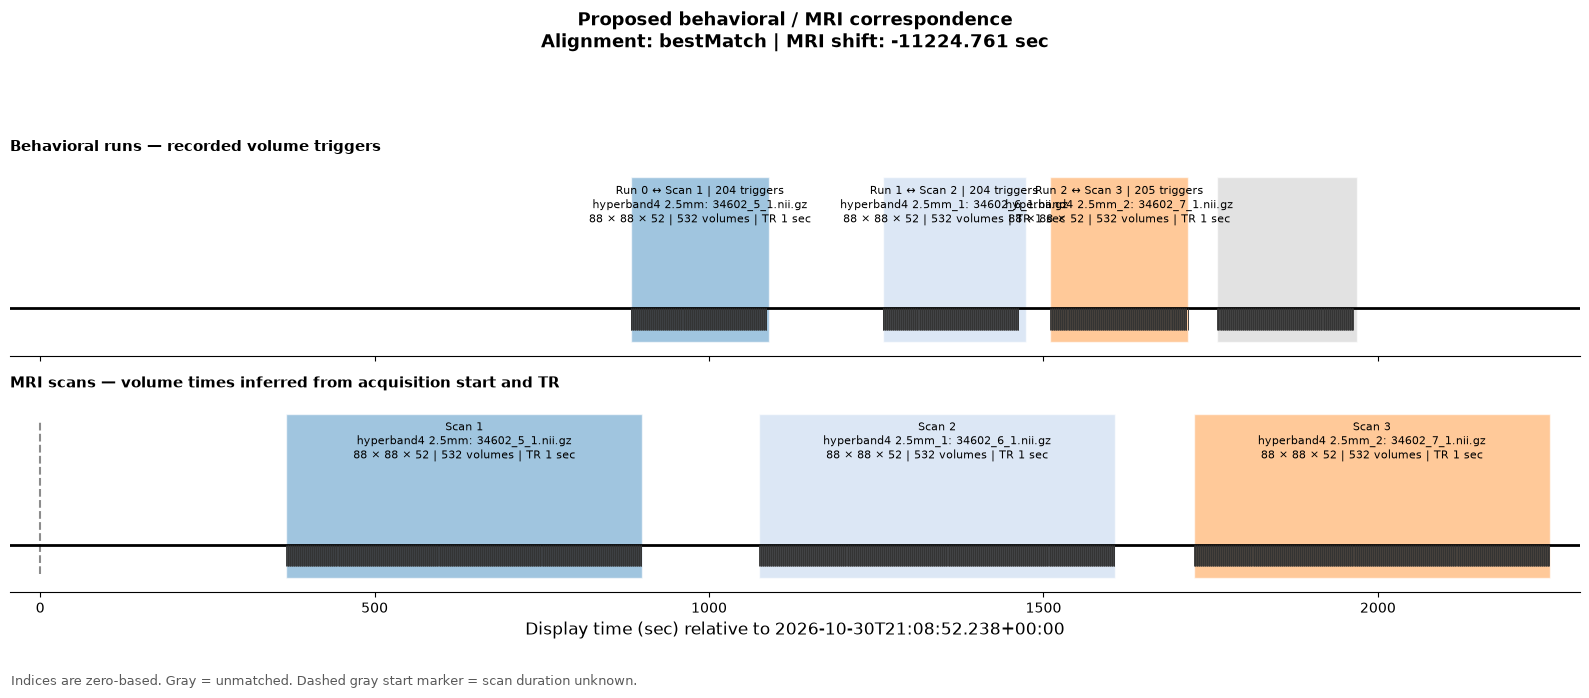

In [11]:
from pgl.pglPlots import pglScanTimelinePlot

# Zero-based (scanIndex, runIndex) pairs.
# Scan 0, the T1, remains unmatched.
proposedMatch = [(1, 0), (2, 1), (3, 2)]

timeline = pglScanTimelinePlot(
    pglRuns=session.runs,
    pglScans=session.mri.scans,
    proposedMatch=proposedMatch,
    alignmentMode='bestMatch',
    volumeMarkerStyle='tick'
)

print(f"MRI shift: {timeline.getAlignmentOffset():+.3f} sec")
timeline.show()

In [13]:
def testChooserCopy():
    """Verify independent selection state and preserved filesystem backing."""
    import copy
    from fsspec.implementations.memory import MemoryFileSystem
    from pgl.pglChoose import pglChooseSession, pglChooseRun

    filesystem = MemoryFileSystem()
    runPath = "/chooserCopyTest/session/run"
    filesystem.makedirs(runPath, exist_ok=True)

    original = pglChooseSession(
        name="session",
        dataPath="/chooserCopyTest/session",
        filesystem=filesystem,
        entries=[]
    )
    leaf = pglChooseRun(
        name="run",
        dataPath=runPath,
        filesystem=filesystem
    )
    leaf.isSelected = False
    original.childList = [leaf]

    copied = copy.deepcopy(original)
    copiedLeaf = copied.childList[0]

    assert copied is not original
    assert copied.childList is not original.childList
    assert copiedLeaf is not leaf
    assert copied.filesystem is filesystem
    assert copiedLeaf.filesystem is filesystem
    assert copiedLeaf.dataPath == leaf.dataPath
    assert copiedLeaf.filesystem.isdir(copiedLeaf.dataPath)
    assert copiedLeaf._run is None

    copiedLeaf.isSelected = True
    assert leaf.isSelected is False

    print("Chooser copy tests passed.")


testChooserCopy()

Chooser copy tests passed.
